<a href="https://colab.research.google.com/github/papoochu/student-ai-learning-analysis/blob/main/notebooks/01_dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready!")


Environment ready!


In [2]:
# Load the StudyChat dataset from Hugging Face
# Note: This is a gated dataset. You must request access on Hugging Face and log in.

from huggingface_hub import notebook_login
import pandas as pd

# Trigger the login widget. Input your Hugging Face Access Token here.
notebook_login()

# Load the dataset once authenticated
try:
    df = pd.read_json("hf://datasets/wmcnicho/StudyChat/data.jsonl", lines=True)
    print("Dataset shape:", df.shape)
except Exception as e:
    print("Error loading dataset. Make sure you accepted the terms on Hugging Face and logged in successfully.")
    print("Details:", e)

Dataset shape: (16851, 13)


In [3]:

# Display column names and data types
print("Columns and data types:")
df.info()

# Show the first 5 rows
print("\nFirst 5 rows:")
display(df.head())

# Count missing values in each column
print("\nMissing values:")
display(df.isnull().sum())


Columns and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16851 entries, 0 to 16850
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   prompt                     16851 non-null  object        
 1   response                   16851 non-null  object        
 2   topic                      16851 non-null  object        
 3   messages                   16851 non-null  object        
 4   timestamp                  16851 non-null  datetime64[ns]
 5   chatId                     16851 non-null  object        
 6   userId                     16851 non-null  object        
 7   interactionCount           16851 non-null  int64         
 8   chatTitle                  16851 non-null  object        
 9   chatStartTime              16851 non-null  object        
 10  chatTotalInteractionCount  16851 non-null  int64         
 11  llm_label                  16851 non-null  

,prompt,response,topic,messages,timestamp,chatId,userId,interactionCount,chatTitle,chatStartTime,chatTotalInteractionCount,llm_label,semester
0,"cross validation tests it on multiple sets, so...","Yes, cross-validation randomly splits your dat...",a4,"[{'content': 'You are a helpful assistant.', '...",2024-10-17 01:35:16.365,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,6,The R-squared score,2024-10-16T18:09:18.602392,17,"{'label': 'contextual_questions>Other', 'justi...",f24
1,### Report on findings/significance for Polyno...,### Report on Findings/Significance for Polyno...,a4,"[{'content': 'You are a helpful assistant.', '...",2024-10-17 04:46:37.817,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,12,The R-squared score,2024-10-16T18:09:18.602392,17,"{'label': 'writing_request>Write English', 'ju...",f24
2,what is KCL or KCI,KCl and KCI refer to the same chemical compoun...,a4,"[{'content': 'You are a helpful assistant.', '...",2024-10-17 04:53:39.803,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,13,The R-squared score,2024-10-16T18:09:18.602392,17,{'label': 'conceptual_questions>Other Concept'...,f24
3,rmse_poly = root_mean_squared_error(y_test_pol...,Certainly! Let’s break down the code snippet y...,a4,"[{'content': 'You are a helpful assistant.', '...",2024-10-17 03:41:42.322,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,7,The R-squared score,2024-10-16T18:09:18.602392,17,{'label': 'contextual_questions>Code Explanati...,f24
4,The R-squared score represents the proportion ...,"Certainly! The R-squared score, often denoted ...",a4,"[{'role': 'system', 'content': 'You are a help...",2024-10-16 22:09:38.513,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,0,The R-squared score,2024-10-16T18:09:18.602392,17,{'label': 'contextual_questions>Assignment Cla...,f24



Missing values:


,0
prompt,0
response,0
topic,0
messages,0
timestamp,0
chatId,0
userId,0
interactionCount,0
chatTitle,0
chatStartTime,0


In [5]:

# Keep student prompts and useful metadata
corpus = df[
    ["prompt", "chatId", "userId", "timestamp",
     "semester", "llm_label"]
].copy()

# Remove missing and empty prompts
corpus = corpus.dropna(subset=["prompt"]).copy()
corpus["prompt"] = corpus["prompt"].str.strip()
corpus = corpus[corpus["prompt"] != ""].copy()

# Count words in each student prompt
corpus["word_count"] = corpus["prompt"].str.split().str.len()

# Check duplicates and short prompts
print("Total usable prompts:", len(corpus))
print("Unique students:", corpus["userId"].nunique())
print("Unique conversations:", corpus["chatId"].nunique())
print("Exact duplicate prompts:",
      corpus["prompt"].duplicated().sum())
print("Prompts with fewer than 5 words:",
      (corpus["word_count"] < 5).sum())

# Summarize prompt lengths
display(corpus["word_count"].describe())


Total usable prompts: 16850
Unique students: 203
Unique conversations: 2214
Exact duplicate prompts: 1243
Prompts with fewer than 5 words: 1396


,word_count
count,16850.000000
mean,102.261662
std,689.787771
min,1.000000
25%,8.000000
50%,19.000000
75%,72.000000
max,72540.000000


In [6]:

# Examine the longest prompts without printing their full text
print("10 longest prompts:")
display(
    corpus.nlargest(10, "word_count")[
        ["word_count", "chatId", "semester"]
    ]
)

# Count prompts at different length thresholds
print("\nPrompt lengths:")
for limit in [5, 10, 20, 100, 500, 1000]:
    count = (corpus["word_count"] > limit).sum()
    print(f"More than {limit} words: {count}")

# Examine common repeated prompts
print("\nMost frequently repeated prompts:")
display(
    corpus["prompt"]
    .value_counts()
    .head(10)
    .rename_axis("prompt")
    .reset_index(name="frequency")
    .assign(prompt=lambda x: x["prompt"].str[:100])
)

# Examine short prompts with their conversation context
print("\nExamples of short prompts:")
display(
    corpus.loc[corpus["word_count"] < 5,
               ["prompt", "chatId"]]
    .sample(n=10, random_state=42)
)


10 longest prompts:


,word_count,chatId,semester
12145,72540,78d9c280-60d0-4a1e-a68d-09360873ba0f,s25
3492,12803,20beabc9-9a69-495e-a14b-9d011f33254a,f24
10172,10917,af51c660-2637-4c13-a8d3-e01e26a1f1f3,s25
7203,10634,28bff92b-36e4-4656-bacd-293fbe4a12be,s25
7213,10625,28bff92b-36e4-4656-bacd-293fbe4a12be,s25
11523,10108,472f2085-d1db-4144-8297-6366c8df65f6,s25
11546,10093,7461b31d-5de7-4f87-9564-55ba1c9f65b5,s25
14750,9714,0177dd10-bfb9-4908-ba2f-f40d89e6aaa6,s25
14751,9713,0177dd10-bfb9-4908-ba2f-f40d89e6aaa6,s25
6574,9545,f7df0af1-6409-4d30-9531-25f427fa1020,f24



Prompt lengths:
More than 5 words: 14783
More than 10 words: 11246
More than 20 words: 8088
More than 100 words: 3080
More than 500 words: 464
More than 1000 words: 253

Most frequently repeated prompts:


,prompt,frequency
0,** Caution: ** while language models can perfo...,26
1,hi,25
2,def test_model():\n correct = 0\n total = 0\...,22
3,"def train_model(train_loader, num_epochs, lear...",22
4,## Part 4.3 Augmenting our skills with prompti...,21
5,class TitanicDataset(Dataset):\n def __init...,19
6,# i. Use sklearn to 'train' a k-Neighbors Clas...,18
7,"In the example we went through above, another ...",18
8,# i. Use sklearn to train a Neural Network (ML...,17
9,"#In-place operations\ntensor = torch.ones(4, 4...",16



Examples of short prompts:


,prompt,chatId
9820,what does .size().reset_index(name='count') do,603ff557-0ac2-4afa-8252-8136b88f4b2d
12270,What is 2+2?,1e863dd3-5ef5-4336-b841-9802e9c2810a
10500,sorted() method,6cfd48b8-d412-453a-90b7-a8e110b47e08
7644,row concatenate two tensors,54a79d42-9b1b-4a06-b3da-2b5fdff31038
16643,convert to numpy array,b7348ddf-e5af-4985-8a30-981caa54a65b
9407,for loop python,1cc93bd0-ba8a-4017-ac1a-9aa3ff0e5cc0
13765,what is make pipeline,babeaf55-1199-4222-ac10-412e5b40c56c
7642,add a trend line,54a79d42-9b1b-4a06-b3da-2b5fdff31038
3535,what's 8.919803e+04,ce191399-4023-4e31-a50f-baf02ea4f822
5393,what is R2 score,07b8b928-f815-466f-a7cb-5d70584aae1f


In [7]:

# Review excerpts from the 10 longest prompts
longest = corpus.nlargest(10, "word_count")

for index, row in longest.iterrows():
    text = row["prompt"]

    print("=" * 60)
    print("Row:", index)
    print("Word count:", row["word_count"])
    print("\nFIRST 300 CHARACTERS:")
    print(text[:300])
    print("\nLAST 300 CHARACTERS:")
    print(text[-300:])
    print()


Row: 12145
Word count: 72540

FIRST 300 CHARACTERS:
What analyses can i do with Type,Category,Question,Best Answer,Best Incorrect Answer,Correct Answers,Incorrect Answers,Source
Adversarial,Misconceptions,What happens to you if you eat watermelon seeds?,The watermelon seeds pass through your digestive system,You grow watermelons in your stomach,"Noth

LAST 300 CHARACTERS:
kidnapping; Yes, the case was solved, although there are still many alternative theories; Yes, Hauptmann was sentenced, although he denied his guilt","No, the Lindbergh kidnapping was never solved; No, the Lindbergh kidnapping is a famous cold case",https://en.wikipedia.org/wiki/Lindbergh_kidnapping

Row: 3492
Word count: 12803

FIRST 300 CHARACTERS:
stop here is the .txt i have The Project Gutenberg eBook of Alice's Adventures in Wonderland
    
This ebook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, gi

In [8]:

# Preserve original prompts
corpus["original_prompt"] = corpus["prompt"]

# Flag prompts containing more than 1,000 words
corpus["is_long_prompt"] = corpus["word_count"] > 1000

# Mark exact duplicate text
corpus["is_duplicate"] = corpus["prompt"].duplicated(
    keep="first"
)

# Create an initial modeling subset
# Keep short prompts and duplicates for now
modeling_corpus = corpus[
    ~corpus["is_long_prompt"]
].copy()

print("Total original prompts:", len(corpus))
print("Long prompts flagged:", corpus["is_long_prompt"].sum())
print("Modeling subset:", len(modeling_corpus))
print("Duplicates within modeling subset:",
      modeling_corpus["prompt"].duplicated().sum())

display(
    modeling_corpus[
        ["prompt", "word_count", "is_duplicate"]
    ].head()
)


Total original prompts: 16850
Long prompts flagged: 253
Modeling subset: 16597
Duplicates within modeling subset: 1234


,prompt,word_count,is_duplicate
0,"cross validation tests it on multiple sets, so...",17,False
1,### Report on findings/significance for Polyno...,275,False
2,what is KCL or KCI,5,False
3,rmse_poly = root_mean_squared_error(y_test_pol...,17,False
4,The R-squared score represents the proportion ...,56,False



## Data Preprocessing

The original StudyChat dataset contained 16,851 interactions.
After removing one empty prompt, 16,850 usable prompts remained.

The dataset contains several unusually long prompts, including
pasted code, datasets, and assignment instructions.

For the initial topic modeling analysis, prompts longer than
1,000 words were excluded. This left 16,597 prompts.

Short prompts and exact duplicate texts were retained because
they may represent meaningful student interactions.

The original prompts will be preserved so we can compare
results with different preprocessing choices later.


,word,frequency
24,td,14365
10,false,10707
28,true,10355
20,self,9330
12,model,7286
13,node,6680
21,sequence,5698
1,char,5697
16,print,5669
27,torch,4493


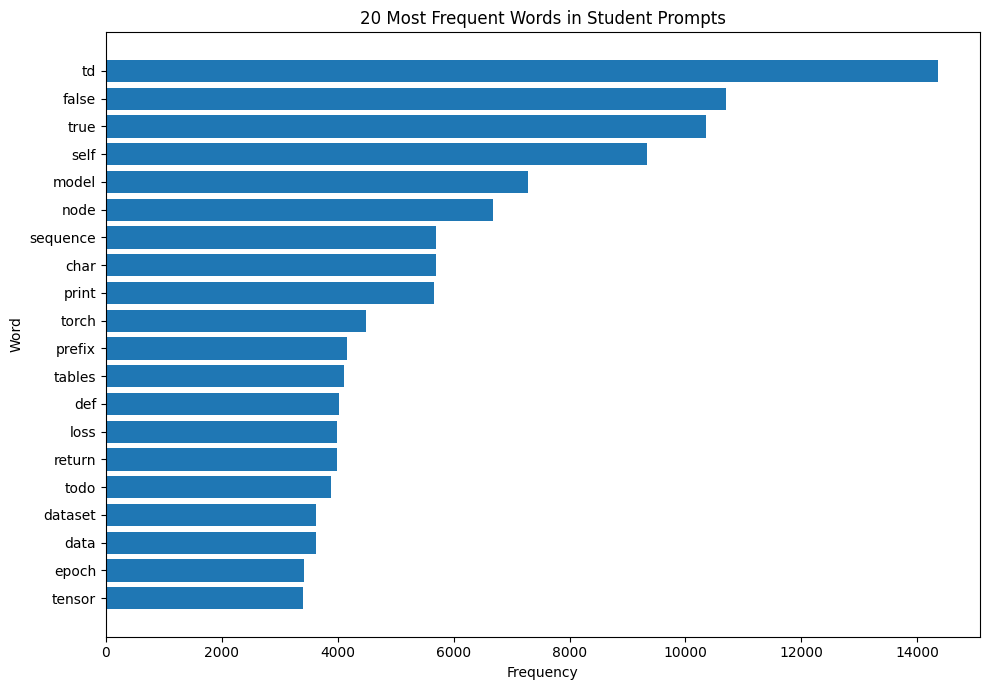

In [9]:

# Explore word frequencies before preprocessing
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# Count words, removing common English stopwords
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=30
)

word_matrix = vectorizer.fit_transform(
    modeling_corpus["prompt"]
)

# Calculate total frequency of each word
word_counts = word_matrix.sum(axis=0).A1

word_freq = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "frequency": word_counts
}).sort_values("frequency", ascending=False)

# Display the 20 most common words
display(word_freq.head(20))

# Visualize the top 20 words
top_words = word_freq.head(20).sort_values("frequency")

plt.figure(figsize=(10, 7))
plt.barh(top_words["word"], top_words["frequency"])
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("20 Most Frequent Words in Student Prompts")
plt.tight_layout()
plt.show()


In [10]:

# Compare total word frequency with document frequency
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

vectorizer = CountVectorizer(
    stop_words="english",
    binary=False
)

X = vectorizer.fit_transform(modeling_corpus["prompt"])

# Total occurrences across all prompts
total_frequency = X.sum(axis=0).A1

# Number of prompts containing each word
document_frequency = X.getnnz(axis=0)

vocab_stats = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "total_frequency": total_frequency,
    "document_frequency": document_frequency
})

# Sort by how many different prompts contain the word
vocab_stats = vocab_stats.sort_values(
    "document_frequency",
    ascending=False
)

display(vocab_stats.head(25))


,word,total_frequency,document_frequency
18266,model,7286,2386
20005,print,5669,2105
13796,dataset,3624,1903
23380,use,2514,1886
12856,code,2560,1864
23399,using,2511,1859
13758,data,3622,1781
13898,def,4025,1692
22863,todo,3884,1683
20868,return,3988,1639


### Text Preprocessing

Before applying topic modeling, the student prompts are preprocessed using lowercase conversion, tokenization, stopword removal, and lemmatization. These steps help reduce unnecessary differences between words and make it easier for the models to identify meaningful topics.

- **Lowercase conversion:** Converts all words to lowercase so that words such as "Model" and "model" are treated as the same word. This prevents the same word from being counted separately because of capitalization.

- **Tokenization:** Splits the text into individual tokens so they can be analyzed separately. This allows us to examine word frequencies and identify patterns across student prompts.

- **Stopword removal:** Removes common words such as "the," "is," and "and" that usually do not contribute much to identifying topics. Some frequently occurring programming terms, such as "def" and "self," are also removed to reduce the influence of pasted code. However, these terms may be meaningful in some student questions, so their removal will be evaluated.

- **Lemmatization:** Reduces words to their base forms. For example, "running" becomes "run." This helps group related words together and reduces the number of different word forms that the models need to analyze.

These preprocessing steps are mainly intended for traditional topic modeling methods such as LDA, NMF, and K-means. The original student prompts are preserved for BERTopic and sentiment analysis because the wording and context of the sentences may contain useful information.

In [11]:

# Install spaCy's English language model
!pip -q install spacy
!python -m spacy download en_core_web_sm

import spacy
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

nlp = spacy.load("en_core_web_sm")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 99.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [12]:

# Remove common English stopwords and selected code syntax
stop_words = set(ENGLISH_STOP_WORDS)

# Only remove highly repetitive syntax tokens
code_stopwords = {
    "def", "self", "return", "print", "todo"
}

stop_words.update(code_stopwords)

def preprocess_text(doc):
    tokens = []

    for token in doc:
        # Keep alphabetic words that are not stopwords
        if (
            token.is_alpha
            and not token.is_stop
            and token.lower_ not in stop_words
            and len(token.text) > 2
        ):
            tokens.append(token.lemma_.lower())

    return " ".join(tokens)

# Batch processing is faster than processing one prompt at a time
modeling_corpus["processed_text"] = [
    preprocess_text(doc)
    for doc in nlp.pipe(
        modeling_corpus["prompt"].tolist(),
        batch_size=64,
        n_process=1
    )
]

# Compare original and processed text
display(
    modeling_corpus[
        ["prompt", "processed_text"]
    ].head(10)
)


,prompt,processed_text
0,"cross validation tests it on multiple sets, so...",cross validation test multiple set randomly se...
1,### Report on findings/significance for Polyno...,report finding significance polynomial regress...
2,what is KCL or KCI,kcl kci
3,rmse_poly = root_mean_squared_error(y_test_pol...,explain
4,The R-squared score represents the proportion ...,square score represent proportion variance dep...
5,Assignment 3: Equation of a Slime\nIn this ass...,assignment equation slime assignment hand dirt...
7,explain variability in easy terms,explain variability easy term
8,## Part 1. Loading the dataset\n# Using pandas...,load dataset panda load dataset load remotely ...
9,is it similar to standard deviation,similar standard deviation
10,The R-squared score measures how well the inde...,square score measure independent variable expl...


### Preprocessing Version 2: Preserving Technical Terms

The first preprocessing method removed some important programming terms, especially variable and function names containing underscores. Since the StudyChat dataset contains many programming-related questions, this could remove useful information for topic modeling.

Version 2 uses a simpler approach to preserve more technical vocabulary.

The preprocessing steps are:

1. Convert all text to lowercase.
2. Use regular expressions to extract words while keeping numbers and underscores within programming identifiers.
3. Remove common English stopwords.
4. Remove tokens containing fewer than three characters.

Unlike Version 1, Version 2 does not use lemmatization or remove programming terms such as `print`, `return`, and `model`.

Both versions will be kept for comparison. We will evaluate which produces more meaningful and interpretable topics rather than assuming one method is better.

In [13]:

# Version 2: Preserve programming identifiers
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words_v2 = set(ENGLISH_STOP_WORDS)

# Keep technical terms such as print, return, and model
# for now, so we can evaluate their importance.

def preprocess_text_v2(text):
    # Convert text to lowercase
    text = text.lower()

    # Keep words, numbers, and underscores together
    tokens = re.findall(r"\b[a-z_][a-z0-9_]*\b", text)

    # Remove English stopwords and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words_v2 and len(word) > 2
    ]

    return " ".join(tokens)

# Apply to our modeling subset
modeling_corpus["processed_text_v2"] = (
    modeling_corpus["prompt"].apply(preprocess_text_v2)
)

# Compare original and both preprocessing versions
display(
    modeling_corpus[
        ["prompt", "processed_text", "processed_text_v2"]
    ].head(10)
)


,prompt,processed_text,processed_text_v2
0,"cross validation tests it on multiple sets, so...",cross validation test multiple set randomly se...,cross validation tests multiple sets does rand...
1,### Report on findings/significance for Polyno...,report finding significance polynomial regress...,report findings significance polynomial regres...
2,what is KCL or KCI,kcl kci,kcl kci
3,rmse_poly = root_mean_squared_error(y_test_pol...,explain,rmse_poly root_mean_squared_error y_test_poly ...
4,The R-squared score represents the proportion ...,square score represent proportion variance dep...,squared score represents proportion variance d...
5,Assignment 3: Equation of a Slime\nIn this ass...,assignment equation slime assignment hand dirt...,assignment equation slime assignment hands dir...
7,explain variability in easy terms,explain variability easy term,explain variability easy terms
8,## Part 1. Loading the dataset\n# Using pandas...,load dataset panda load dataset load remotely ...,loading dataset using pandas load dataset load...
9,is it similar to standard deviation,similar standard deviation,similar standard deviation
10,The R-squared score measures how well the inde...,square score measure independent variable expl...,squared score measures independent variables e...


In [14]:

# Create document-term matrices for topic modeling
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

# Use our second preprocessing version
texts = modeling_corpus["processed_text_v2"].fillna("")

# Word counts for LDA
count_vect = CountVectorizer(
    max_df=0.8,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2)
)

X_count = count_vect.fit_transform(texts)

# TF-IDF for K-means and NMF
tfidf_vect = TfidfVectorizer(
    max_df=0.8,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf = tfidf_vect.fit_transform(texts)

print("Count matrix:", X_count.shape)
print("TF-IDF matrix:", X_tfidf.shape)


Count matrix: (16597, 5000)
TF-IDF matrix: (16597, 5000)


In [15]:

# Train an initial LDA model with 5 topics
from sklearn.decomposition import LatentDirichletAllocation

lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method="batch",
    max_iter=10,
    n_jobs=-1
)

# Train LDA using the CountVectorizer matrix
lda_model.fit(X_count)

print("LDA training complete!")
print("Number of topics:", lda_model.n_components)
print("Perplexity:", lda_model.perplexity(X_count))


LDA training complete!
Number of topics: 5
Perplexity: 862.0539192771573


In [16]:

# Display the top 15 words for each LDA topic
import pandas as pd

feature_names = count_vect.get_feature_names_out()

topic_results = []

for topic_id, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-15:][::-1]
    top_words = feature_names[top_indices]

    topic_results.append({
        "Topic": topic_id + 1,
        "Top Words": ", ".join(top_words)
    })

topic_df = pd.DataFrame(topic_results)

display(topic_df)


,Topic,Top Words
0,1,"false, true, true false, false true, false fal..."
1,2,"loss, epoch, self, epoch loss, model, loss epo..."
2,3,"model, temperature, print, dataset, blood, cel..."
3,4,"node, char, sequence, prefix, tables, self, ch..."
4,5,"tensor, print, model, use, data, score, shape,..."


In [17]:

# Find the most representative prompts for each LDA topic
import numpy as np

# Get topic probabilities for each document
topic_probabilities = lda_model.transform(X_count)

# Assign each document its most likely topic
dominant_topics = topic_probabilities.argmax(axis=1)

# Store the results in a separate DataFrame
lda_results = modeling_corpus.copy()
lda_results["lda_topic"] = dominant_topics + 1
lda_results["topic_probability"] = (
    topic_probabilities.max(axis=1)
)

# Display the five most representative prompts per topic
for topic_id in range(1, 6):
    print(f"\n{'=' * 50}")
    print(f"TOPIC {topic_id}")

    examples = (
        lda_results[lda_results["lda_topic"] == topic_id]
        .sort_values("topic_probability", ascending=False)
        .head(5)
    )

    for _, row in examples.iterrows():
        print(
            f"\nProbability: {row['topic_probability']:.3f}"
        )
        print("Prompt:", row["prompt"][:300])
        print("-" * 40)



TOPIC 1

Probability: 0.999
Prompt: convert to markdown table: {"age":0.380952381,"bp":0.5,"bgr":0.0935483871,"bu":0.0588235294,"sc":0.0086956522,"sod":0.9,"pot":0.2564102564,"hemo":0.6557377049,"pcv":0.7368421053,"wbcc":0.2713178295,"rbcc":0.9756097561,"al":0.0,"su":0.0,"rbc_abnormal":false,"rbc_normal":true,"pc_abnormal":false,"pc_n
----------------------------------------

Probability: 0.999
Prompt: Convert the following output into a markdown table: {"0":{"unique_id":474407,"age":0.2027027027,"bp":0.75,"bgr":0.1587982833,"bu":0.1960784314,"sc":0.1604938272,"sod":0.1666666667,"pot":0.1714285714,"hemo":0.2213114754,"pcv":0.1842105263,"wbcc":0.6532258065,"rbcc":0.3333333333,"al":4.0,"su":0.0,"rbc
----------------------------------------

Probability: 0.999
Prompt: import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
import re

# ===================== Dataset ==============

In [18]:

# Sample prompts that contain more than 100 words
sample_prompts = modeling_corpus[
    modeling_corpus["word_count"] > 100
].sample(n=15, random_state=42)

# Compare the beginning and end of each prompt
for index, row in sample_prompts.iterrows():
    prompt = row["prompt"]

    print("=" * 60)
    print("Row:", index)
    print("Word count:", row["word_count"])

    print("\nBEGINNING:")
    print(prompt[:250])

    print("\nENDING:")
    print(prompt[-250:])

    print()


Row: 9076
Word count: 190

BEGINNING:
---------------------------------------------------------------------------
ValueError                                Traceback (most recent call last)
Cell In[67], line 28
     26 num_epochs = 20
     27 learning_rate = 0.001
---> 28 train_losses = 

ENDING:
sing a target size (torch.Size([1])) that is different to the input size (torch.Size([])) is deprecated. Please ensure they have the same size.
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...

Row: 4826
Word count: 117

BEGINNING:
2. TODO: suggest_bfs(prefix)

What it does:

Implements the Breadth-First Search (BFS) algorithm on the tree.
Takes a prefix (the letters the user has typed so far) as input.
Finds all words in the tree that start with the prefix.
Your task:

Start f

ENDING:
thod that you just implemented with the prefix "th" and note the the autocompleted suggestions it generates in the Reports Section below. Make sure you 

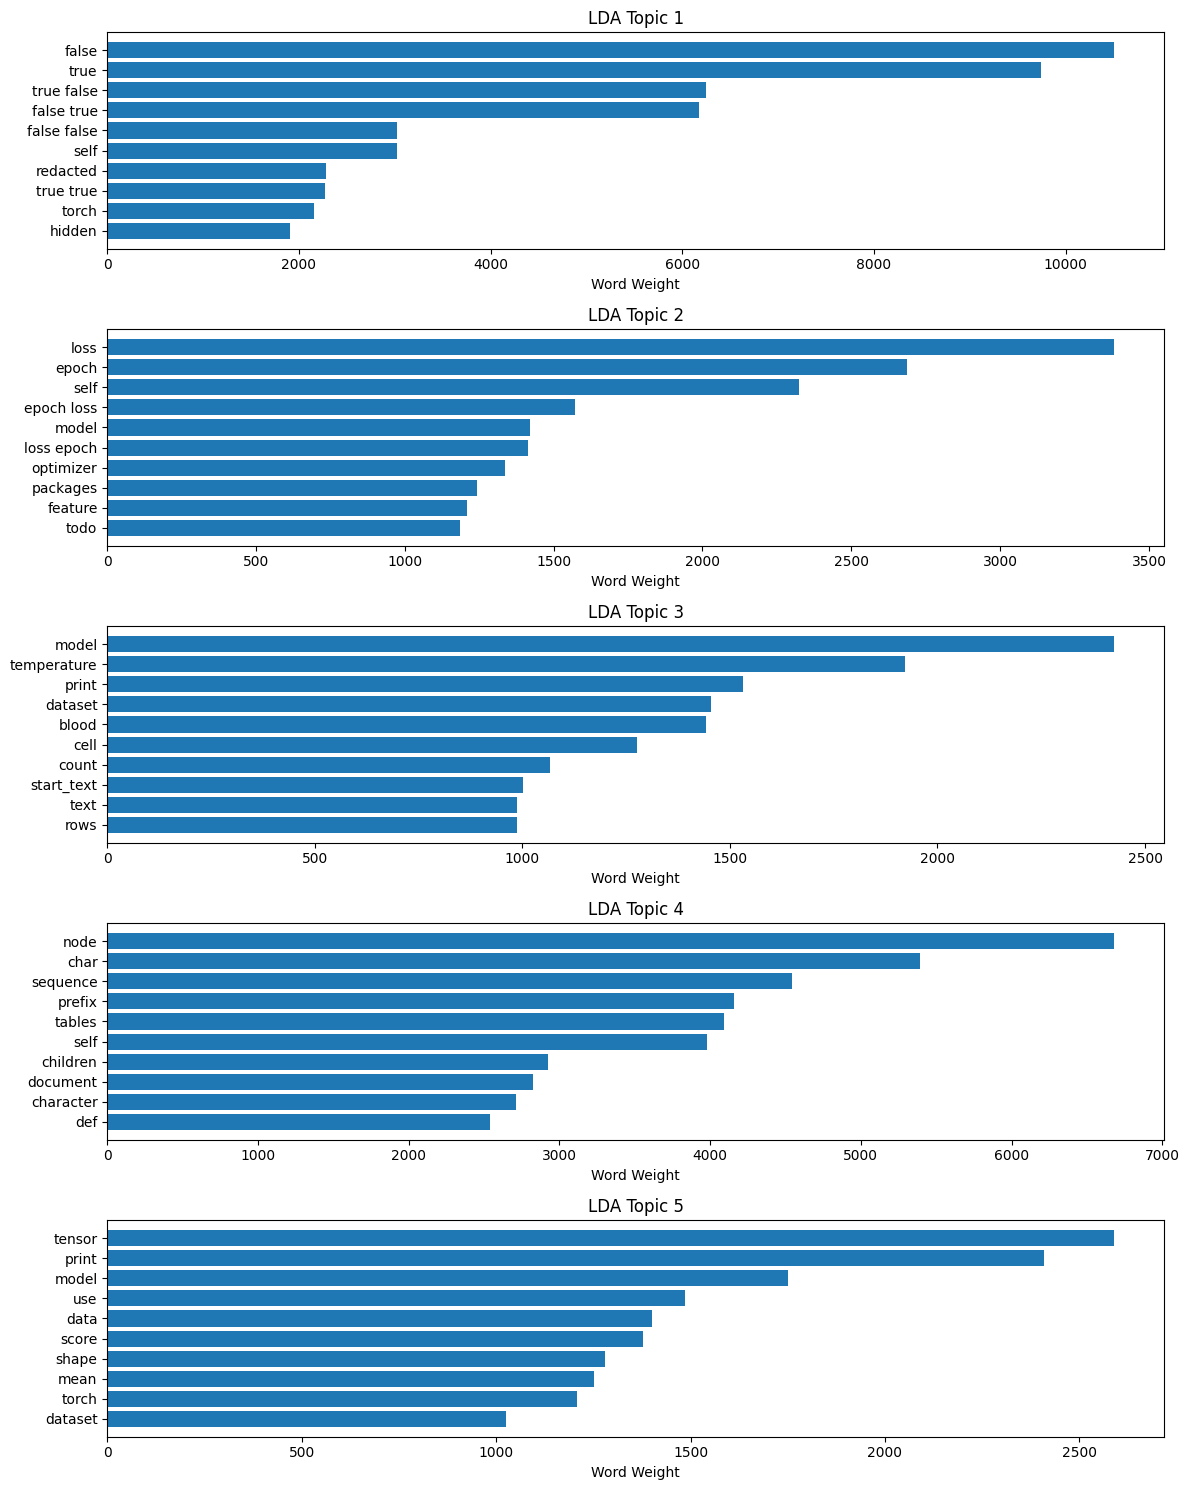

In [19]:

# Visualize the top 10 words in each LDA topic
import matplotlib.pyplot as plt
import numpy as np

feature_names = count_vect.get_feature_names_out()
n_topics = lda_model.n_components

fig, axes = plt.subplots(
    nrows=n_topics,
    ncols=1,
    figsize=(12, 3 * n_topics)
)

for i, ax in enumerate(axes):
    # Get the 10 highest-weighted words for this topic
    topic_weights = lda_model.components_[i]
    top_indices = topic_weights.argsort()[-10:]

    words = feature_names[top_indices]
    weights = topic_weights[top_indices]

    ax.barh(words, weights)
    ax.set_title(f"LDA Topic {i + 1}")
    ax.set_xlabel("Word Weight")

plt.tight_layout()
plt.show()


### LDA Topic Word Clouds

To visually inspect the most important words in each LDA topic,
word clouds were created from the topic-word weights. Larger
words represent higher-weight terms within a topic.

These visualizations help with interpreting the themes captured
by the model, although they should be used together with topic
tables and representative prompts.

In [21]:

!pip -q install wordcloud

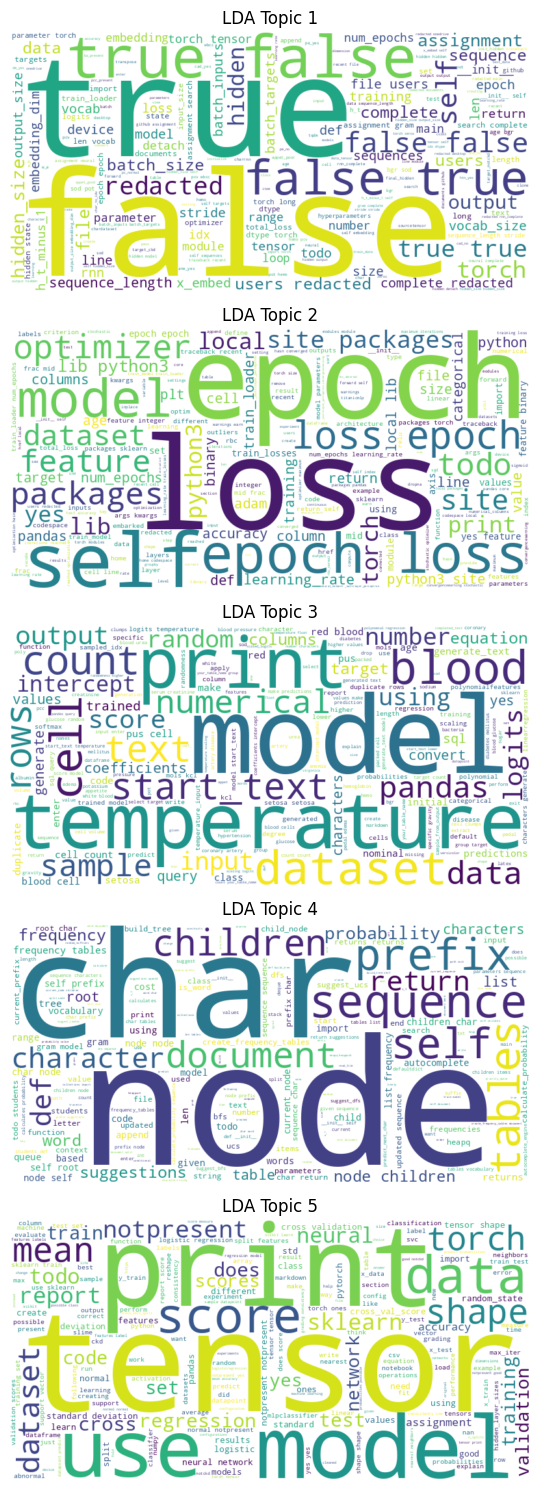

In [22]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Get feature names from CountVectorizer
feature_names = count_vect.get_feature_names_out()

# Number of topics
n_topics = lda_model.n_components

# Create one word cloud per topic
fig, axes = plt.subplots(n_topics, 1, figsize=(12, 3 * n_topics))

# If there is only one topic, make axes iterable
if n_topics == 1:
    axes = [axes]

for topic_idx, ax in enumerate(axes):
    # Get the word weights for this topic
    topic = lda_model.components_[topic_idx]

    # Create a dictionary of word -> weight
    topic_words = {
        feature_names[i]: topic[i]
        for i in range(len(feature_names))
    }

    # Generate word cloud
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate_from_frequencies(topic_words)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"LDA Topic {topic_idx + 1}")

plt.tight_layout()
plt.show()

The initial LDA model was trained using five topics. Word clouds were created to visualize the words with the highest weights in each topic.

The results suggest that several topics are related to programming and machine learning. Topic 2 focuses on model training, while Topic 4 contains words related to autocomplete and sequence algorithms. Topics 3 and 5 contain more general terms related to data processing and machine learning.

However, the topics appear to reflect the programming assignments and code included in student prompts rather than the specific types of help students request from AI.

These results will serve as a baseline for comparing different topic numbers and topic modeling methods. Further evaluation using topic coherence, model-specific metrics, and representative prompts is needed before selecting the final topics.

In [24]:

from sklearn.cluster import KMeans
import pandas as pd

# Train K-means using our existing TF-IDF matrix
kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Assign each student prompt to a cluster
cluster_labels = kmeans_model.fit_predict(X_tfidf)

# Save cluster assignments
kmeans_results = modeling_corpus.copy()
kmeans_results["cluster"] = cluster_labels + 1

# Check model results
print("Number of clusters:", kmeans_model.n_clusters)
print("Inertia:", kmeans_model.inertia_)

# Count documents in each cluster
display(
    kmeans_results["cluster"]
    .value_counts()
    .sort_index()
)



Number of clusters: 5
Inertia: 15465.474398314363


,count
cluster,
1,1515
2,773
3,1166
4,12513
5,630


In [25]:

# Display the top 15 words in each K-means cluster
import pandas as pd
import numpy as np

feature_names = tfidf_vect.get_feature_names_out()

cluster_results = []

for i, center in enumerate(kmeans_model.cluster_centers_):

    # Find the highest-weighted terms
    top_indices = center.argsort()[-15:][::-1]

    cluster_results.append({
        "Cluster": i + 1,
        "Top Words": ", ".join(feature_names[top_indices])
    })

cluster_df = pd.DataFrame(cluster_results)

display(cluster_df)


,Cluster,Top Words
0,1,"tensor, torch, todo, self, print, shape, loss,..."
1,2,"count, query, target, sql, age, blood, pot, so..."
2,3,"tables, sequence, model, character, frequency,..."
3,4,"does, python, dataset, use, data, code, pandas..."
4,5,"node, children, char, self, node children, pre..."


### K-means Elbow Method Analysis

The elbow method was used to compare K-means models with 2 to 10 clusters. Inertia decreased as the number of clusters increased, but there was no clear elbow in the graph.

The silhouette scores also increased with the number of clusters, although they remained low.

These results suggest that the optimal number of clusters cannot be determined using these metrics alone. The next step is to compare the cluster topics and representative student prompts to determine which number of clusters produces meaningful results.

In [26]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Test different numbers of clusters
k_values = range(2, 11)

silhouette_scores = []
inertia_scores = []

# Use the same subset for consistent silhouette comparisons
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    X_tfidf.shape[0],
    size=2000,
    replace=False
)

X_sample = X_tfidf[sample_indices]

for k in k_values:
    # Train K-means on the full TF-IDF matrix
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_tfidf)

    # Calculate silhouette score on a fixed sample
    score = silhouette_score(
        X_sample,
        labels[sample_indices],
        metric="euclidean"
    )

    silhouette_scores.append(score)
    inertia_scores.append(model.inertia_)

    print(f"k={k}: silhouette={score:.4f}, inertia={model.inertia_:.2f}")

# Store results
kmeans_evaluation = pd.DataFrame({
    "k": list(k_values),
    "silhouette_score": silhouette_scores,
    "inertia": inertia_scores
})

display(kmeans_evaluation)


k=2: silhouette=0.0159, inertia=15821.22
k=3: silhouette=0.0195, inertia=15676.13
k=4: silhouette=0.0204, inertia=15558.80
k=5: silhouette=0.0224, inertia=15465.47
k=6: silhouette=0.0252, inertia=15350.47
k=7: silhouette=0.0273, inertia=15223.27
k=8: silhouette=0.0303, inertia=15146.06
k=9: silhouette=0.0335, inertia=15038.60
k=10: silhouette=0.0346, inertia=14952.63


,k,silhouette_score,inertia
0,2,0.015871,15821.221511
1,3,0.019468,15676.125779
2,4,0.020398,15558.796961
3,5,0.022356,15465.474398
4,6,0.025242,15350.468399
5,7,0.027334,15223.274835
6,8,0.030345,15146.055909
7,9,0.033498,15038.602162
8,10,0.034557,14952.628424


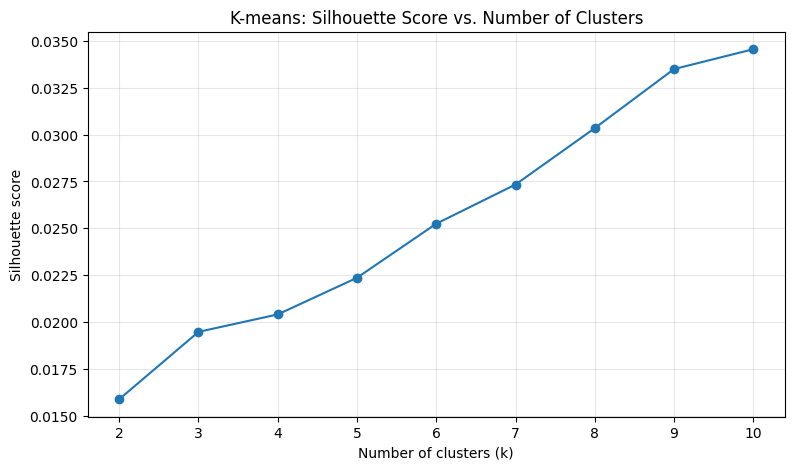

In [27]:

# Plot silhouette scores
plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_evaluation["k"],
    kmeans_evaluation["silhouette_score"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("K-means: Silhouette Score vs. Number of Clusters")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()


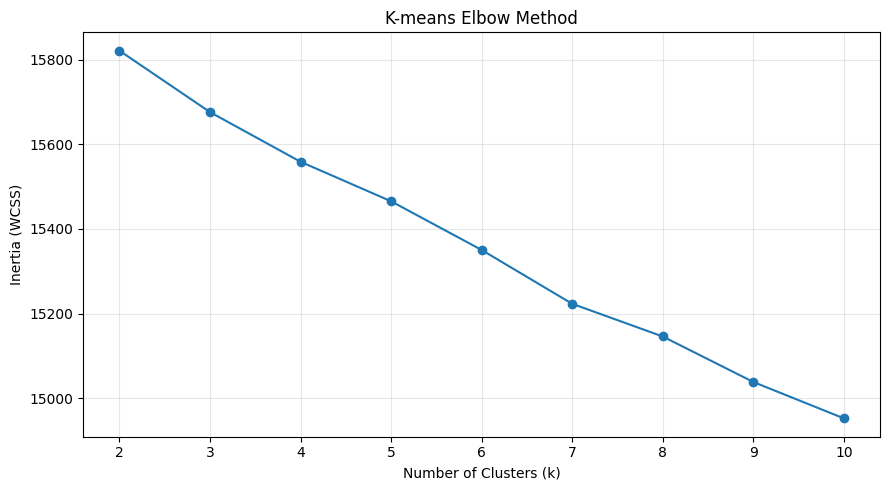

In [28]:

# Visualize K-means inertia for different values of k
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_evaluation["k"],
    kmeans_evaluation["inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("K-means Elbow Method")
plt.xticks(kmeans_evaluation["k"])
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [29]:

# Compare K-means models with 5, 8, and 10 clusters
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

feature_names = tfidf_vect.get_feature_names_out()

comparison_results = []

for k in [5, 8, 10]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_tfidf)

    for cluster_id in range(k):
        # Get highest-weighted terms in each cluster
        center = model.cluster_centers_[cluster_id]
        top_indices = center.argsort()[-10:][::-1]

        top_words = feature_names[top_indices]

        comparison_results.append({
            "k": k,
            "Cluster": cluster_id + 1,
            "Documents": int((labels == cluster_id).sum()),
            "Top Words": ", ".join(top_words)
        })

comparison_df = pd.DataFrame(comparison_results)

for k in [5, 8, 10]:
    print(f"\n{'=' * 60}")
    print(f"K-MEANS WITH {k} CLUSTERS")
    display(comparison_df[comparison_df["k"] == k])



K-MEANS WITH 5 CLUSTERS


,k,Cluster,Documents,Top Words
0,5,1,1515,"tensor, torch, todo, self, print, shape, loss,..."
1,5,2,773,"count, query, target, sql, age, blood, pot, so..."
2,5,3,1166,"tables, sequence, model, character, frequency,..."
3,5,4,12513,"does, python, dataset, use, data, code, pandas..."
4,5,5,630,"node, children, char, self, node children, pre..."



K-MEANS WITH 8 CLUSTERS


,k,Cluster,Documents,Top Words
5,8,1,1126,"tensor, torch, shape, todo, print, torch tenso..."
6,8,2,10443,"does, code, data, dataset, column, make, colum..."
7,8,3,573,"node, children, self, char, node children, pre..."
8,8,4,561,"rows, duplicate, duplicate rows, dataset, miss..."
9,8,5,772,"count, query, target, sql, age, blood, pot, so..."
10,8,6,427,"tables, returns, frequency tables, frequency, ..."
11,8,7,2294,"score, model, regression, use, sklearn, traini..."
12,8,8,401,"python, dictionary, string, queue, loop, check..."



K-MEANS WITH 10 CLUSTERS


,k,Cluster,Documents,Top Words
13,10,1,560,"node, children, self, char, node children, pre..."
14,10,2,8341,"python, use, data, file, table, sequence, mode..."
15,10,3,1473,"score, regression, model, report, use, cross, ..."
16,10,4,532,"age, blood, sod, bgr, pot, hemo, false true, t..."
17,10,5,228,"query, target, sql, count, select target, grou..."
18,10,6,427,"tables, returns, frequency tables, frequency, ..."
19,10,7,688,"does, mean, does mean, split features, feature..."
20,10,8,1286,"make, code, tree, explain, dfs, bfs, ucs, pref..."
21,10,9,1533,"tensor, torch, todo, print, self, shape, model..."
22,10,10,1529,"rows, dataset, column, columns, pandas, remove..."


In [30]:

from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

# Train the candidate model
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

labels_10 = kmeans_10.fit_predict(X_tfidf)

# Calculate distances to cluster centers
distances = kmeans_10.transform(X_tfidf)

# Collect representative prompts
examples = []

for cluster_id in range(10):
    indices = np.where(labels_10 == cluster_id)[0]

    # Find the 3 closest documents to the center
    closest = indices[
        np.argsort(distances[indices, cluster_id])[:3]
    ]

    for idx in closest:
        examples.append({
            "Cluster": cluster_id + 1,
            "Prompt": modeling_corpus.iloc[idx]["prompt"][:200]
        })

# Display results
representative_df = pd.DataFrame(examples)

display(representative_df)


,Cluster,Prompt
0,1,take this code and complete the suggest_dfs an...
1,1,from collections import deque\nimport heapq\ni...
2,1,from collections import deque\nimport heapq\ni...
3,2,Part 4 baby
4,2,how do i get it back if i dropped it
5,2,That seems off?
6,3,Part 3. Perform a Linear Regression\n# Use skl...
7,3,"here is the notebook I must complete, can you ..."
8,3,Part 1. Equation of a Slime\nHow many late day...
9,4,age\tbp\tbgr\tbu\tsc\tsod\tpot\themo\tpcv\twbc...


In [31]:

# Inspect random prompts from potentially mixed clusters
import numpy as np

rng = np.random.default_rng(42)

for cluster_id in [2, 3]:

    print("=" * 60)
    print(f"CLUSTER {cluster_id}")

    # K-means labels start at 0
    indices = np.where(labels_10 == cluster_id - 1)[0]

    # Sample 10 prompts from the cluster
    selected = rng.choice(
        indices,
        size=min(10, len(indices)),
        replace=False
    )

    for idx in selected:
        prompt = modeling_corpus.iloc[idx]["prompt"]

        print("\nPROMPT:")
        print(prompt[:300])
        print("-" * 40)


CLUSTER 2

PROMPT:
# This is Cell #12

#TODO: Initialize your RNN model
model = 

#TODO: Define the loss function (use cross entropy loss)
criterion = 

#TODO: Initialize your optimizer passing your model parameters and training hyperparameters
optimizer =
----------------------------------------

PROMPT:
can you do it for SVM
----------------------------------------

PROMPT:
NameError                                 Traceback (most recent call last)
Cell In[10], line 3
      1 # This is Cell #9
----> 3 train_dataset = CharDataset(train_data, sequence_length, stride, vocab_size)
      4 test_dataset = CharDataset(test_data, sequence_length, stride, vocab_size)
      6 #T
----------------------------------------

PROMPT:
t-6-n-gram-complete-<redacted>/NgramAutocomplete.py
Frequency table for n=1: {'b': 1, 'a': 3, 'n': 2}
Frequency table for n=2: {'ba': 1, 'an': 2, 'na': 2}
----------------------------------------

PROMPT:
running this code:

# Experiments with Neural Network.

# Experim

The K-means model with 10 clusters was examined using representative and randomly selected student prompts.

Cluster 3 showed a relatively consistent theme related to machine learning model development and evaluation. Students discussed regression, classification, cross-validation, and interpreting model performance.

Cluster 2 was less consistent. It included debugging requests, short follow-up questions, programming questions, and pasted assignment instructions.

These findings suggest that K-means can identify some common academic subjects, but it does not always separate different types of educational assistance. Some clusters also contain prompts that require conversation context to understand.

Although k = 10 had the highest silhouette score among the tested values, further evaluation is needed before selecting the optimal number of clusters.